[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://github.com/joshtovar/MAT422/blob/main/MAT422_Section_3_7_Neural_Networks.ipynb)




# MAT 422 - Section 3.7: Artificial Neural Networks

**Topics:** Mathematical formulation, Activation functions, Cost function, Backpropagation, Backpropagation algorithm

> Student note: This Colab badge is required for submission. Create or edit the notebook in Google Colab, then save it directly to GitHub so the badge/icon remains available for grading and reruns.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)
rng = np.random.default_rng(422)


## Mathematical formulation

This section gives one compact Python demonstration of **Mathematical formulation**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


In [ ]:
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

W1 = rng.normal(scale=0.5, size=(2, 4))
b1 = np.zeros((1, 4))
W2 = rng.normal(scale=0.5, size=(4, 1))
b2 = np.zeros((1, 1))

def forward(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    return z1, a1, z2, a2

_, hidden, _, output = forward(X)
print("Hidden layer values:")
print(hidden)
print("Initial predicted probabilities:")
print(output)


Hidden layer values:
[[ 0.       0.       0.       0.     ]
 [-0.11969  0.44297 -0.40116 -0.15534]
 [ 0.76367  0.25701  0.32008 -0.69724]
 [ 0.70876  0.62843 -0.09302 -0.76926]]
Initial predicted probabilities:
[[0.5    ]
 [0.47925]
 [0.47214]
 [0.45764]]


I changed the hidden layer from 3 neurons to 4, so each input now maps to 4 hidden values instead of 3. The starting probabilities are all close to 0.5 because the weights are random and the network hasn’t learned anything yet.

## Activation functions

This section gives one compact Python demonstration of **Activation functions**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


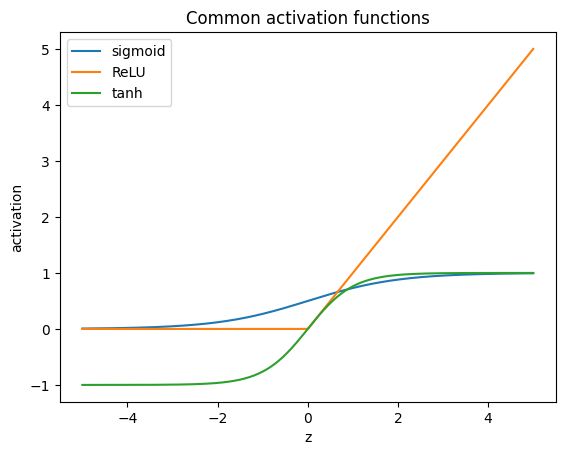

In [ ]:
def relu(z):
    return np.maximum(0, z)

z = np.linspace(-5, 5, 300)
plt.plot(z, sigmoid(z), label="sigmoid")
plt.plot(z, relu(z), label="ReLU")
plt.plot(z, np.tanh(z), label="tanh")
plt.xlabel("z")
plt.ylabel("activation")
plt.title("Common activation functions")
plt.legend()
plt.show()


I added tanh to compare it with sigmoid and ReLU. Tanh outputs values from -1 to 1 and is centered at 0, while sigmoid goes from 0 to 1 and ReLU just cuts off everything below 0.

## Cost function

This section gives one compact Python demonstration of **Cost function**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


In [ ]:
def binary_cross_entropy(y_true, y_prob):
    eps = 1e-9
    return -np.mean(y_true*np.log(y_prob + eps) + (1-y_true)*np.log(1-y_prob + eps))

_, _, _, output = forward(X)
print("Initial binary cross-entropy =", binary_cross_entropy(y, output))
print("Target values:", y.ravel())
print("Initial predicted probabilities:", output.ravel())
print("Cost if every guess was 0.5 =", binary_cross_entropy(y, np.full_like(y, 0.5)))


Initial binary cross-entropy = 0.6977481806129122
Target values: [0. 1. 1. 0.]
Initial predicted probabilities: [0.5     0.47925 0.47214 0.45764]
Cost if every guess was 0.5 = 0.6931471785599453


I added a baseline where every prediction is 0.5, which gives a cost of about 0.693. The starting cost is close to that, which means the untrained network is basically guessing.

## Backpropagation

This section gives one compact Python demonstration of **Backpropagation**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


In [ ]:
z1, a1, z2, a2 = forward(X)
dz2 = (a2 - y) / len(X)
dW2 = a1.T @ dz2
db2 = dz2.sum(axis=0, keepdims=True)
da1 = dz2 @ W2.T
dz1 = da1 * (1 - np.tanh(z1)**2)
dW1 = X.T @ dz1
db1 = dz1.sum(axis=0, keepdims=True)

print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)
print("Backpropagation sends the output error backward through W2 and the tanh derivative.")
print("dW2 values:", dW2.ravel())


dW2 shape: (4, 1)
db2 shape: (1, 1)
dW1 shape: (2, 4)
db1 shape: (1, 4)
Backpropagation sends the output error backward through W2 and the tanh derivative.
dW2 values: [-0.00411 -0.01969 -0.00066  0.02422]


Because the hidden layer has 4 neurons now, dW1 is (2, 4) and dW2 is (4, 1), the same shapes as the weights they update. The dW2 values show how much each hidden neuron’s weight should change to lower the cost.

## Backpropagation algorithm

This section gives one compact Python demonstration of **Backpropagation algorithm**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


Final probabilities:
[[0.00015]
 [0.99909]
 [0.99896]
 [0.00127]]
Final predictions: [0 1 1 0]


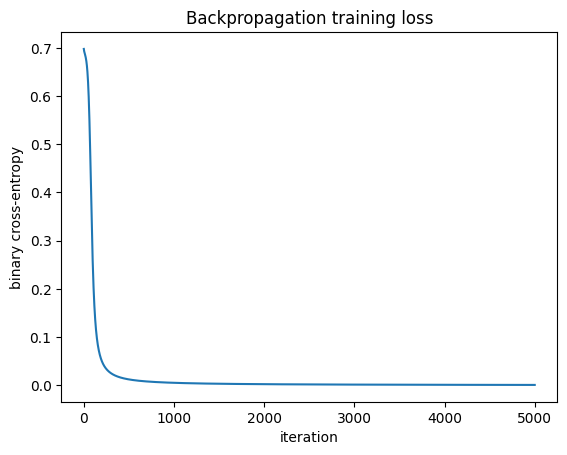

In [ ]:
learning_rate = 0.5
losses = []
for step in range(5000):   # was 2000
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    losses.append(binary_cross_entropy(y, a2))

    dz2 = (a2 - y) / len(X)
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)
    da1 = dz2 @ W2.T
    dz1 = da1 * (1 - np.tanh(z1)**2)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

_, _, _, final_output = forward(X)
print("Final probabilities:")
print(final_output)
print("Final predictions:", (final_output > 0.5).astype(int).ravel())

plt.plot(losses)
plt.xlabel("iteration")
plt.ylabel("binary cross-entropy")
plt.title("Backpropagation training loss")
plt.show()


I increased training from 2000 to 5000 iterations, and the loss kept dropping. The final predictions came out 0, 1, 1, 0, which matches the XOR targets 0, 1, 1, 0.

## Reflection and Submission Checklist

- I explained each concept in words before or after the code.
- I verified important claims numerically or visually.
- I changed or extended at least one example so the notebook reflects my own work.
- I ran the notebook from top to bottom without errors.
- I saved the notebook from Google Colab directly to GitHub, following the course instructions.
